In [1]:
import numpy as np
import matplotlib.pyplot as plt
from blg_dot import dot_states     # gerçek BLG dot çözücüsü
from blg_kp import g1

U0, Ldot, D_op = 0.020, 15.0, 0.167

# memoize'lı Delta01(D_ext)
_cache = {}
def d01(D):
    k = round(D, 7)
    if k not in _cache:
        b, _ = dot_states(D, U0, Ldot)
        _cache[k] = b[1] - b[0]
    return _cache[k]

print("static Delta01 =", round(1e3*d01(D_op), 4), "meV")  # ~0.9888 bekliyoruz

L_box=120.0 nm, dq=0.0524, qmax=0.5 -> N_pw=293, dim=1172
static Delta01 = 0.9888 meV


In [2]:
# === (c) A-HARİTASI: etki nerede en büyük + operasyonel sınır ===
NPH = 24
ph = np.linspace(0, 2*np.pi, NPH, endpoint=False)
cosph = np.cos(ph)

def periodavg(D, A):
    return d01(D) if A == 0.0 else np.mean([d01(D + A*c) for c in cosph])

def slope(A, h=0.004):
    return (periodavg(D_op+h, A) - periodavg(D_op-h, A)) / (2*h)

def min_inst(A):                      # periyot içi anlık minimum Delta01
    return min(d01(D_op + A*c) for c in cosph)

A_list = np.array([0.0, 0.01, 0.02, 0.03, 0.05, 0.07, 0.09, 0.11, 0.13, 0.15])  # eV
s0 = abs(slope(0.0))

print(f"{'A(meV)':>7} {'<D01>_T':>9} {'min_inst':>9} {'|slope|':>9} {'T2*_oran':>9}")
rows = []
for A in A_list:
    avg, s, mi = periodavg(D_op, A), abs(slope(A)), min_inst(A)
    rows.append((A, avg, mi, s, s0/s))
    print(f"{1e3*A:>7.0f} {1e3*avg:>9.4f} {1e3*mi:>9.4f} {s:>9.4f} {s0/s:>9.4f}")
rows = np.array(rows)

 A(meV)   <D01>_T  min_inst   |slope|  T2*_oran
      0    0.9888    0.9888    0.0276    1.0000
     10    1.0012    0.7382    0.0275    1.0041
     20    1.0371    0.5382    0.0272    1.0158
     30    1.0938    0.3852    0.0267    1.0344
     50    1.2536    0.1899    0.0254    1.0867
     70    1.4498    0.0910    0.0239    1.1542
     90    1.6584    0.0430    0.0223    1.2387
    110    1.8610    0.0201    0.0203    1.3584
    130    2.0370    0.0099    0.0172    1.6052
    150    1.9469    0.0045    0.0578    0.4770


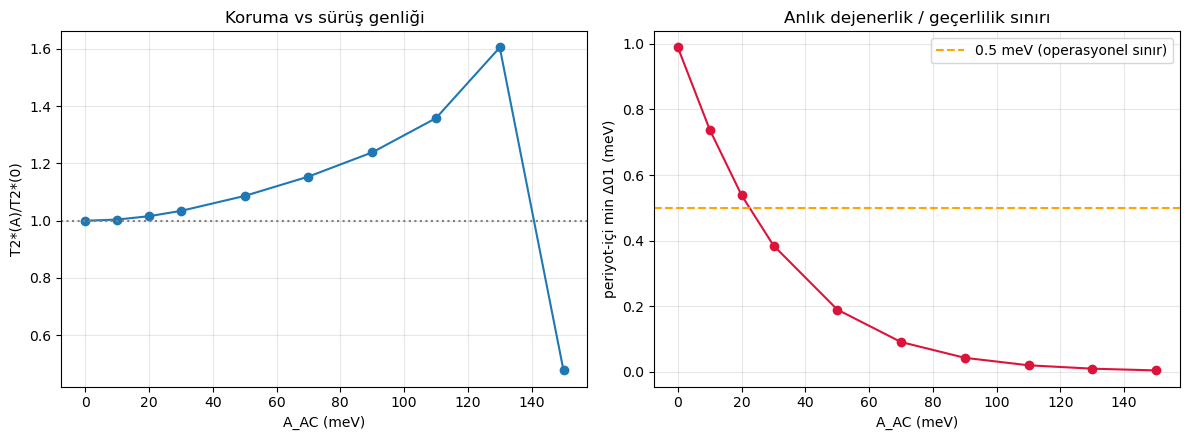

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(1e3*rows[:,0], rows[:,4], "o-")
ax[0].axhline(1, ls=":", c="gray"); ax[0].set_xlabel("A_AC (meV)")
ax[0].set_ylabel("T2*(A)/T2*(0)"); ax[0].set_title("Koruma vs sürüş genliği")
ax[0].grid(alpha=.3)
ax[1].plot(1e3*rows[:,0], 1e3*rows[:,2], "o-", c="crimson")
ax[1].axhline(0.5, ls="--", c="orange", label="0.5 meV (operasyonel sınır)")
ax[1].set_xlabel("A_AC (meV)"); ax[1].set_ylabel("periyot-içi min Δ01 (meV)")
ax[1].set_title("Anlık dejenerlik / geçerlilik sınırı")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [4]:
import numpy as np
from scipy.linalg import eigh
from blg_ac_fast import H0, Ddiag, d01

D_op = 0.167

def setup(D_c):
    H = H0 + np.diag(D_c*Ddiag).astype(complex)
    E, W = eigh(H)
    Vt = (W.conj().T * Ddiag) @ W
    mu, Q = eigh(Vt)
    Qd = Q.conj().T
    pos = np.where(E > 1e-6)[0]
    return E, mu, Q, Qd, pos[0], pos[1]

def evolve_period(E, mu, Q, Qd, psi0, A, omega, nstep):
    T = 2*np.pi/omega; dt = T/nstep
    free = np.exp(-1j*E*dt/2)
    psi = psi0.copy()
    for k in range(nstep):
        psi = free*psi
        c = A*np.cos(omega*(k+0.5)*dt)
        psi = Q @ (np.exp(-1j*dt*c*mu) * (Qd @ psi))
        psi = free*psi
    return psi, T

def floquet_full(D_c, A, omega, nstep=300):
    E, mu, Q, Qd, q0, q1 = setup(D_c)
    dim = len(E)
    e0 = np.zeros(dim, dtype=complex); e0[q0]=1
    e1 = np.zeros(dim, dtype=complex); e1[q1]=1
    p0, T = evolve_period(E, mu, Q, Qd, e0, A, omega, nstep)
    p1, _ = evolve_period(E, mu, Q, Qd, e1, A, omega, nstep)
    M = np.array([[np.vdot(e0,p0), np.vdot(e0,p1)],
                  [np.vdot(e1,p0), np.vdot(e1,p1)]])
    leak0 = 1-(abs(np.vdot(e0,p0))**2+abs(np.vdot(e1,p0))**2)
    leak1 = 1-(abs(np.vdot(e0,p1))**2+abs(np.vdot(e1,p1))**2)
    leak = max(leak0, leak1)
    Uq,s,Vh = np.linalg.svd(M); Mu = Uq@Vh
    ph = np.angle(np.linalg.eigvals(Mu))
    dphi = abs(((ph[0]-ph[1]+np.pi)%(2*np.pi))-np.pi)
    return leak, dphi/T

if __name__ == "__main__":
    d0 = d01(D_op); omega = 6.6*d0
    print(f"static Delta01={1e3*d0:.4f} meV, hw={1e3*omega:.3f} meV (FULL Hilbert, no projection)")
    lk0, sp0 = floquet_full(D_op, 0.0, omega)
    print(f"ANCHOR A=0: leak={lk0:.2e}, split={1e3*sp0:.5f} meV vs static {1e3*d0:.5f}")
    print(f"\n{'A(meV)':>7} {'LEAKAGE':>10} {'split(meV)':>11}  note")
    for A in (0.0,0.005,0.010,0.015,0.020,0.030,0.050):
        lk, sp = floquet_full(D_op, A, omega)
        note = "2-level OK" if lk<0.05 else ("MARGINAL" if lk<0.2 else "2-LEVEL BROKEN")
        print(f"{1e3*A:>7.0f} {lk:>10.4f} {1e3*sp:>11.4f}  {note}")
    print("\nnstep convergence (A=30 meV): leakage")
    for nst in (200,300,500):
        lk,_ = floquet_full(D_op,0.030,omega,nstep=nst)
        print(f"   nstep={nst}: leak={lk:.4f}")

static Delta01=0.9888 meV, hw=6.526 meV (FULL Hilbert, no projection)
ANCHOR A=0: leak=9.73e-10, split=0.98884 meV vs static 0.98884

 A(meV)    LEAKAGE  split(meV)  note
      0     0.0000      0.9888  2-level OK
      5     0.0286      0.9841  2-level OK
     10     0.1098      0.9701  MARGINAL
     15     0.2310      0.9464  2-LEVEL BROKEN
     20     0.3755      0.9115  2-LEVEL BROKEN
     30     0.6633      0.7967  2-LEVEL BROKEN
     50     0.9522      0.1316  2-LEVEL BROKEN

nstep convergence (A=30 meV): leakage
   nstep=200: leak=0.6636
   nstep=300: leak=0.6633
   nstep=500: leak=0.6632


In [5]:
"""
Static 2D sweet-spot search for the BLG valley qubit.
Charge noise couples to D_ext. A sweet spot = point where
d(Delta01)/d(D_ext) = 0 at a USEFUL (non-vanishing) splitting.
Second control axis: dot depth U0 (separate gate). Scan (D_ext,U0).

Speed: confinement ~ U0 (linear), kinetic split into D=0 part + D*Ddiag.
So H(D,U0) = Kin0 + D*Dmat + U0*Cmat, precomputed once; each grid pt = 1 eigh.
"""
import numpy as np
from scipy.linalg import eigh
from blg_kp import Hkp, bulk_cond_min
from blg_dot import QX, QY, Npw, Vft, L_box

Ldot = 15.0
dim = 4*Npw

# --- precompute the three building blocks ONCE ---
Kin0 = np.zeros((dim, dim), dtype=complex)
for a in range(Npw):
    Kin0[4*a:4*a+4, 4*a:4*a+4] = Hkp(QX[a], QY[a], 0.0, +1)

Dmat = np.zeros(dim)                      # layer-asymmetry diagonal (the D_ext operator)
for a in range(Npw):
    Dmat[4*a+0]=+0.5; Dmat[4*a+1]=+0.5; Dmat[4*a+2]=-0.5; Dmat[4*a+3]=-0.5
Dmat = np.diag(Dmat).astype(complex)

Cmat = np.zeros((dim, dim), dtype=complex)  # confinement at U0=1 (scales linearly)
for a in range(Npw):
    for b in range(Npw):
        val = Vft(QX[a]-QX[b], QY[a]-QY[b], 1.0, Ldot)   # U0=1
        if val != 0.0:
            for o in range(4):
                Cmat[4*a+o, 4*b+o] += val

_bulkcache = {}
def gap(D):
    k=round(D,6)
    if k not in _bulkcache: _bulkcache[k]=bulk_cond_min(D)
    return _bulkcache[k]

def dot_split(D, U0):
    H = Kin0 + D*Dmat + U0*Cmat
    E = eigh(H, eigvals_only=True)
    cmin = gap(D)
    bound = E[(E>1e-6) & (E<cmin)]
    return (bound[1]-bound[0]) if len(bound)>=2 else np.nan

if __name__ == "__main__":
    # VERIFY: U0=0.020 slice must reproduce Table 1
    print("VERIFY vs Table 1 (U0=20 meV):")
    for D in (0.05,0.10,0.15,0.167,0.20):
        print(f"  D={D:.3f}  Delta01={1e3*dot_split(D,0.020):.3f} meV")
    print("(expect 5.130, 3.471, 1.524, 0.989, 0.347)\n")

    # 2D scan: find d(Delta01)/dD_ext = 0 at useful splitting
    Ds = np.linspace(0.08, 0.22, 15)
    U0s = np.array([0.012,0.016,0.020,0.024,0.028,0.032,0.040])
    h = 0.004
    print("2D sweet-spot scan: |d Delta01/d D_ext| (meV/eV), * = local min in D at useful gap")
    print("U0\\D   " + "  ".join(f"{1e3*D:5.0f}" for D in Ds))
    best = []
    for U0 in U0s:
        row=[]
        for D in Ds:
            sp = dot_split(D,U0)
            dp = (dot_split(D+h,U0)-dot_split(D-h,U0))/(2*h)
            row.append((D,sp,abs(dp)))
        # find min |slope| among points with useful splitting (>0.3 meV)
        useful=[(D,sp,ds) for (D,sp,ds) in row if sp>3e-4]
        line=f"{1e3*U0:4.0f}  "
        for (D,sp,ds) in row:
            mark="*" if (sp>3e-4 and ds==min(x[2] for x in useful)) else " "
            line+=f"{ds:6.3f}{mark}"
        print(line)
        if useful:
            bm=min(useful,key=lambda x:x[2])
            best.append((U0,)+bm)
    print("\nBest (lowest |slope|) per U0, at useful splitting:")
    print(f"{'U0(meV)':>8}{'D_ext':>8}{'D01(meV)':>10}{'|slope|':>9}")
    for U0,D,sp,ds in best:
        print(f"{1e3*U0:>8.0f}{D:>8.3f}{1e3*sp:>10.3f}{ds:>9.3f}")

VERIFY vs Table 1 (U0=20 meV):
  D=0.050  Delta01=5.130 meV
  D=0.100  Delta01=3.471 meV
  D=0.150  Delta01=1.524 meV
  D=0.167  Delta01=0.989 meV
  D=0.200  Delta01=0.347 meV
(expect 5.130, 3.471, 1.524, 0.989, 0.347)

2D sweet-spot scan: |d Delta01/d D_ext| (meV/eV), * = local min in D at useful gap
U0\D      80     90    100    110    120    130    140    150    160    170    180    190    200    210    220
  12   0.028  0.031  0.032  0.032  0.030  0.027  0.022  0.017  0.013* 0.009  0.006  0.004  0.003  0.001  0.001 
  16   0.032  0.034  0.036  0.037  0.036  0.035  0.032  0.028  0.023  0.018  0.013* 0.010  0.007  0.005  0.003 
  20   0.035  0.037  0.039  0.040  0.040  0.039  0.038  0.035  0.031  0.026  0.021  0.016  0.012* 0.009  0.006 
  24   0.038  0.040  0.041  0.043  0.043  0.043  0.042  0.040  0.037  0.033  0.028  0.023  0.018  0.014  0.010*
  28   0.040  0.042  0.044  0.045  0.046  0.046  0.045  0.044  0.042  0.038  0.034  0.029  0.024  0.019  0.015*
  32   0.042  0.044  0.046

 CIPALAR (gecmeden hicbir sonuca guvenme)

[Cipa 2] Bulk gap — raporun Tablo 1'i:
   beklenen: 0.100->48.4  0.150->69.8  0.167->76.3 meV
   (2x sapma -> delta konvansiyonu faktor-2 farkli; ±Δ/4 dene)
  [Cipa2] delta_ext= 100.0 meV -> gap= 100.00 meV  (E_c=50.0, E_v=-50.0)  k_c=[-2.094  2.094]
  [Cipa2] delta_ext= 150.0 meV -> gap= 150.00 meV  (E_c=75.0, E_v=-75.0)  k_c=[-2.094  2.094]
  [Cipa2] delta_ext= 167.0 meV -> gap= 167.00 meV  (E_c=83.5, E_v=-83.5)  k_c=[-2.094  2.094]

[Cipa 3] Trigonal warping / C3:
  [Cipa3] C3 bileseni=69.1239 meV  (C2=1248.7377); C3>>C2 ve C3>0 -> trigonal warping VAR

[Cipa 4] Gapless @ delta=0:
  [Cipa2] delta_ext=   0.0 meV -> gap= 125.53 meV  (E_c=62.8, E_v=-62.8)  k_c=[ 2.121 -2.121]
  [Cipa4] delta=0 gap=125.526 meV (≈0 bekleniyor)

[Cipa 5] Kramers:
  [Cipa5] max|E(k)-E(-k)|=0.00e+00 meV (≈0 bekleniyor)

  Bulk bant grafigi...


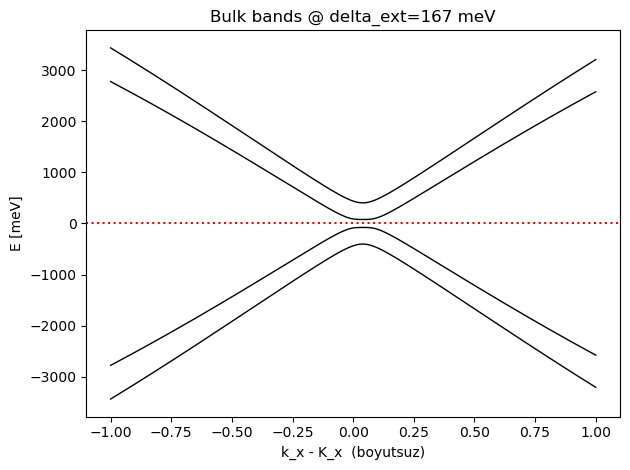


 ASAMA 1-2: dot bagli durumlar + minivalley
  [Cipa2] delta_ext= 167.0 meV -> gap= 167.00 meV  (E_c=83.5, E_v=-83.5)  k_c=[-2.094  2.094]
  atom sayisi = 383,794  | sigma = 73.5 meV


: 

In [8]:
#!/usr/bin/env python3
# =============================================================================
#  blg_tb_dot_kwant.py  —  Atomistik tight-binding BLG kuantum noktasi (KWANT)
#  ASAMA 1-2: iskelet + cipalar + minivalley reproduksiyonu
# =============================================================================
#
#  Kwant Hamiltonyeni kendisi Hermityen kurar ve Bloch fazlarini dogru hesaplar.
#  Bizim isimiz: orgu + hopping'leri dogru tanimlamak ve CIPALARLA dogrulamak.
#
#  CIPALAR (raporundaki disiplinin atomistik versiyonu):
#     Cipa 2 — Bulk gap, raporun Tablo 1'i ile uyusmali   *** EN KRITIK ***
#     Cipa 3 — Trigonal warping / C3 (iletkenlik minimumu 3-katli)
#     Cipa 4 — delta_ext=0 -> gapless
#     Cipa 5 — K vs K' Kramers (TRS)
#     Cipa 6 — Sureklilik limiti: kucuk gap'te TB seviyeleri k·p ile eslesmeli
#
#  Kurulum (sende zaten var):  conda install -c conda-forge kwant
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from math import sqrt, pi, exp

import kwant
import kwant.wraparound
from scipy.sparse.linalg import eigsh

# -----------------------------------------------------------------------------
#  PARAMETRELER  (McCann-Koshino, eV; uzunluklar nm)
# -----------------------------------------------------------------------------
A_LAT = 0.24595
A_CC  = A_LAT / sqrt(3)        # ~0.142 nm

GAMMA0 = -3.16   # katman-ici nn
GAMMA1 =  0.38   # B1-A2 dimer
GAMMA3 =  0.38   # A1-B2 trigonal warping  *** minivalley icin SART ***
GAMMA4 =  0.14   # skew (opsiyonel)
DELTA_PRIME = 0.022   # dimer on-site asimetri (opsiyonel)

# -----------------------------------------------------------------------------
#  ORGU  —  4 alt-orgu: A1,B1 (alt katman), A2,B2 (ust katman).
#  AB istif: A2 dogrudan B1'in ustunde (ayni xy). 2D'de ust uste binerler;
#  bu kozmetik (farkli family), hopping'ler tag ile tanimlandigindan sorun yok.
# -----------------------------------------------------------------------------
lat = kwant.lattice.general(
    prim_vecs=[(A_LAT, 0.0), (A_LAT/2, A_LAT*sqrt(3)/2)],
    basis=[(0.0, -A_CC/2),    # A1  (non-dimer)
           (0.0, +A_CC/2),    # B1  (dimer)
           (0.0, +A_CC/2),    # A2  (dimer, B1 ustunde)
           (0.0, 3*A_CC/2)],  # B2  (non-dimer)
    norbs=1,
)
A1, B1, A2, B2 = lat.sublattices

# Hopping'ler:  HoppingKind(delta, fam_a, fam_b) ->  <a, tag+delta | H | b, tag>
def add_hoppings(syst, use_gamma4=False):
    HK = kwant.builder.HoppingKind
    # γ0 katman-ici (her iki katman)
    for d in [(0, 0), (0, -1), (1, -1)]:
        syst[HK(d, B1, A1)] = GAMMA0
        syst[HK(d, B2, A2)] = GAMMA0
    # γ1 dimer (B1-A2, ayni hucre)
    syst[HK((0, 0), A2, B1)] = GAMMA1
    # γ3 trigonal warping (A1-B2)  *** C3: bulk cipasi dogrulayacak ***
    for d in [(0, -1), (1, -1), (1, -2)]:
        syst[HK(d, B2, A1)] = GAMMA3
    # γ4 skew (opsiyonel)
    if use_gamma4:
        for d in [(0, 0), (0, -1), (1, -1)]:
            syst[HK(d, A2, A1)] = GAMMA4
            syst[HK(d, B2, B1)] = GAMMA4

# On-site:  gap (katmana bagli ±Δ/2) + Gauss kuyu.  Bulk'ta U0=0 verilir.
def make_onsite(use_delta_prime=False):
    def onsite(site, delta_ext, U0, L_dot):
        x, y = site.pos
        top = site.family in (A2, B2)
        val = (-delta_ext/2 if top else +delta_ext/2)
        if use_delta_prime and site.family in (B1, A2):
            val += DELTA_PRIME/2
        val += -U0 * exp(-(x*x + y*y) / (2 * L_dot*L_dot))
        return val
    return onsite


# =============================================================================
#  BULK  (wraparound) + CIPALAR 2-3-4-5
#  k_x,k_y wraparound'da boyutsuzdur: tam BZ = [-pi, pi]^2.
# =============================================================================
def make_bulk(use_gamma4=False, use_delta_prime=False):
    sym = kwant.TranslationalSymmetry(lat.vec((1, 0)), lat.vec((0, 1)))
    bulk = kwant.Builder(sym)
    onsite = make_onsite(use_delta_prime)
    for sub in (A1, B1, A2, B2):
        bulk[sub(0, 0)] = onsite
    add_hoppings(bulk, use_gamma4)
    return kwant.wraparound.wraparound(bulk).finalized()

def bulk_energies(fbulk, delta_ext, kx, ky):
    H = fbulk.hamiltonian_submatrix(
        params=dict(delta_ext=delta_ext, U0=0.0, L_dot=15.0, k_x=kx, k_y=ky))
    return np.sort(np.linalg.eigvalsh(H))   # 4 bant

def scan_bz(fbulk, delta_ext, n=121):
    """Tum BZ'yi tara: iletkenlik min / valans max ve iletkenlik min konumu."""
    ks = np.linspace(-pi, pi, n)
    cmin, vmax = +np.inf, -np.inf
    kcmin = None
    for kx in ks:
        for ky in ks:
            E = bulk_energies(fbulk, delta_ext, kx, ky)
            if E[2] < cmin:
                cmin, kcmin = E[2], (kx, ky)
            vmax = max(vmax, E[1])
    return cmin, vmax, kcmin

def anchor_bulk_gap(delta_ext, n=121, **kw):
    fbulk = make_bulk(**kw)
    cmin, vmax, kc = scan_bz(fbulk, delta_ext, n)
    gap = cmin - vmax
    print(f"  [Cipa2] delta_ext={delta_ext*1e3:6.1f} meV -> gap={gap*1e3:7.2f} meV"
          f"  (E_c={cmin*1e3:.1f}, E_v={vmax*1e3:.1f})  k_c={np.round(kc,3)}")
    return gap, cmin, vmax, kc

def anchor_c3(delta_ext, dk=0.15, m=24, **kw):
    """Cipa 3: iletkenlik min konumu (K) etrafinda kucuk halkada acisal modulasyon
       3-katli (C3) olmali -> trigonal warping imzasi."""
    fbulk = make_bulk(**kw)
    _, _, kc = scan_bz(fbulk, delta_ext, n=81)
    th = np.linspace(0, 2*pi, m, endpoint=False)
    Ec = np.array([bulk_energies(fbulk, delta_ext,
                                 kc[0]+dk*np.cos(t), kc[1]+dk*np.sin(t))[2]
                   for t in th])
    # 3-katli Fourier bileseni baskin mi?
    c3 = np.abs(np.sum(Ec*np.exp(-3j*th)))
    c2 = np.abs(np.sum(Ec*np.exp(-2j*th)))
    print(f"  [Cipa3] C3 bileseni={c3*1e3:.4f} meV  (C2={c2*1e3:.4f}); "
          f"C3>>C2 ve C3>0 -> trigonal warping VAR")
    return c3, c2

def anchor_gapless(**kw):
    gap, *_ = anchor_bulk_gap(0.0, n=81, **kw)
    print(f"  [Cipa4] delta=0 gap={gap*1e3:.3f} meV (≈0 bekleniyor)")
    return gap

def anchor_kramers(delta_ext, **kw):
    """Cipa 5: E(k)=E(-k) (TRS) -> bulk spektrumu k ve -k'de ozdes."""
    fbulk = make_bulk(**kw)
    _, _, kc = scan_bz(fbulk, delta_ext, n=81)
    Ek  = bulk_energies(fbulk, delta_ext,  kc[0],  kc[1])
    Emk = bulk_energies(fbulk, delta_ext, -kc[0], -kc[1])
    err = np.max(np.abs(Ek - Emk))*1e3
    print(f"  [Cipa5] max|E(k)-E(-k)|={err:.2e} meV (≈0 bekleniyor)")
    return err

def plot_bulk_bands(delta_ext, **kw):
    fbulk = make_bulk(**kw)
    _, _, kc = scan_bz(fbulk, delta_ext, n=81)
    ts = np.linspace(-1.0, 1.0, 240)
    bands = np.array([bulk_energies(fbulk, delta_ext, kc[0]+t, kc[1]) for t in ts])*1e3
    for b in range(bands.shape[1]):
        plt.plot(ts, bands[:, b], 'k-', lw=1)
    plt.axhline(0, color='r', ls=':')
    plt.xlabel("k_x - K_x  (boyutsuz)"); plt.ylabel("E [meV]")
    plt.title(f"Bulk bands @ delta_ext={delta_ext*1e3:.0f} meV")
    plt.tight_layout(); plt.show()


# =============================================================================
#  KUANTUM NOKTASI  (sonlu flake, shift-invert) + bagli durum filtresi
# =============================================================================
def make_dot(radius, use_gamma4=False, use_delta_prime=False):
    syst = kwant.Builder()
    onsite = make_onsite(use_delta_prime)
    def circle(pos):
        x, y = pos
        return x*x + y*y < radius*radius
    syst[lat.shape(circle, (0, 0))] = onsite
    add_hoppings(syst, use_gamma4)
    return syst.finalized()

def solve_dot(delta_ext, U0, L_dot, radius, n_states=24, sigma=None, **kw):
    if sigma is None:
        _, Ec, _, _ = anchor_bulk_gap(delta_ext, n=61, **kw)
        sigma = Ec - U0/2
    fsyst = make_dot(radius, **kw)
    print(f"  atom sayisi = {len(fsyst.sites):,}  | sigma = {sigma*1e3:.1f} meV")
    H = fsyst.hamiltonian_submatrix(
        params=dict(delta_ext=delta_ext, U0=U0, L_dot=L_dot), sparse=True)
    H = H.tocsc()
    E, psi = eigsh(H, k=n_states, sigma=sigma)
    idx = np.argsort(E)
    return fsyst, E[idx], psi[:, idx]

def classify(fsyst, psi, radius):
    pos = np.array([s.pos for s in fsyst.sites])
    r = np.hypot(pos[:, 0], pos[:, 1])
    prob = np.abs(psi)**2
    prob /= prob.sum(axis=0, keepdims=True)
    rmean = prob.T @ r
    ipr = np.sum(prob**2, axis=0)
    is_dot = rmean < 0.5*radius
    return pos, rmean, ipr, is_dot

def plot_density(fsyst, psi, n, radius):
    pos = np.array([s.pos for s in fsyst.sites])
    p = np.abs(psi[:, n])**2
    plt.figure(figsize=(5, 5))
    plt.scatter(pos[:, 0], pos[:, 1], c=p, s=4, cmap='inferno')
    plt.gca().set_aspect('equal'); plt.colorbar(label=f"|psi_{n}|^2")
    plt.xlim(-radius, radius); plt.ylim(-radius, radius)
    plt.title(f"durum {n}  (C3 trefoil bekleniyor)")
    plt.tight_layout(); plt.show()


# =============================================================================
#  CIPA 6: SURELILIK LIMITI — kendi k·p cozucunle karsilastir
# =============================================================================
def continuum_comparison(delta_ext, U0, L_dot, radius, **kw):
    fsyst, E, psi = solve_dot(delta_ext, U0, L_dot, radius, **kw)
    pos, rmean, ipr, is_dot = classify(fsyst, psi, radius)
    print("\n  TB durumlar (* = dot-lokalize):")
    print("   idx |   E [meV] | <r> [nm] |   IPR    | dot?")
    for i in range(len(E)):
        print(f"   {i:3d} | {E[i]*1e3:8.3f} | {rmean[i]:7.2f} | "
              f"{ipr[i]:.2e} | {'*' if is_dot[i] else ' '}")
    dotE = np.sort(E[is_dot])*1e3
    if len(dotE) >= 2:
        print(f"\n  >> TB Delta_01 = {dotE[1]-dotE[0]:.3f} meV")
        print( "     ^^ KENDI k·p Delta_01 ile karsilastir (Cipa 6).")
    return fsyst, E, psi, is_dot


# =============================================================================
def run_anchors():
    print("="*70 + "\n CIPALAR (gecmeden hicbir sonuca guvenme)\n" + "="*70)
    print("\n[Cipa 2] Bulk gap — raporun Tablo 1'i:")
    print("   beklenen: 0.100->48.4  0.150->69.8  0.167->76.3 meV")
    print("   (2x sapma -> delta konvansiyonu faktor-2 farkli; ±Δ/4 dene)")
    for d in (0.100, 0.150, 0.167):
        anchor_bulk_gap(d, n=121)
    print("\n[Cipa 3] Trigonal warping / C3:");  anchor_c3(0.167)
    print("\n[Cipa 4] Gapless @ delta=0:");       anchor_gapless()
    print("\n[Cipa 5] Kramers:");                 anchor_kramers(0.167)
    print("\n  Bulk bant grafigi...");            plot_bulk_bands(0.167)

def run_stage12():
    print("\n" + "="*70 + "\n ASAMA 1-2: dot bagli durumlar + minivalley\n" + "="*70)
    delta_ext, U0, L_dot, radius = 0.167, 0.020, 15.0, 40.0
    fsyst, E, psi, is_dot = continuum_comparison(delta_ext, U0, L_dot, radius)
    # Dot durumlarinin yogunlugu (C3 trefoil):
    # dot_idx = np.where(is_dot)[0]
    # for n in dot_idx[:3]:
    #     plot_density(fsyst, psi, n, radius)

if __name__ == "__main__":
    run_anchors()      # 1) once cipalar; Cipa 2 Tablo 1 ile uyusmuyorsa DUR
    run_stage12()      # 2) cipalar gectiyse asama 1-2